# **Tiamat - Previsão de Renda Anual Superior ou Igual a 50 Mil Dólares utilizando Machine Learning** 

Autora: Gabriela O. de Lima Cabral

Professor: Daniel Roberto Cassar

Ilum - Escola de ciência

Centro Nacional de Pesquisa em Energia e Materiais (CNPEM)

## **1. Introdução**

Decisões relacionadas à concessão de crédito, contratação de profissionais, distribuição de benefícios e formulação de políticas públicas dependem, em grande medida, de estimativas sobre a renda da população. Nesse contexto, os censos desempenham um papel fundamental, pois permitem compreender como a renda está distribuída e registram informações demográficas, educacionais e ocupacionais dos indivíduos. A partir desses dados, surge a seguinte questão: é possível prever a faixa de renda de uma pessoa com base em suas características pessoais e profissionais?

Neste trabalho, abordaremos esse problema por meio de técnicas de aprendizado de máquina. Dado um conjunto de atributos de um indivíduo, como idade, escolaridade, ocupação, estado civil, horas trabalhadas por semana e ganhos de capital, será desenvolvido um modelo capaz de prever se sua renda anual é superior a 50 mil dólares. Esse limiar é amplamente utilizado em estudos socioeconômicos e caracteriza uma classe minoritária no conjunto de dados. Como consequência, a distribuição das classes é desbalanceada, tornando a acurácia tradicional uma métrica potencialmente enganosa e justificando o uso da acurácia balanceada como principal medida de avaliação.

O objetivo geral deste trabalho é comparar diferentes algoritmos de aprendizado supervisionado nessa tarefa, realizando ajuste sistemático de hiperparâmetros e avaliando sua capacidade de generalização para dados não vistos. Para isso, serão comparados seis algoritmos pertencentes a famílias distintas: regressão logística, k-vizinhos mais próximos (KNN), árvore de decisão, floresta aleatória e gradient boosting. Como referência, será utilizado um modelo baseline que sempre prevê a classe majoritária. Os hiperparâmetros de cada algoritmo, bem como etapas de pré-processamento, incluindo normalização de atributos numéricos, codificação de variáveis categóricas e redução de dimensionalidade, serão otimizados por meio da avaliação de 100 configurações distintas para cada método. Posteriormente, será investigado se as diferenças de desempenho observadas são estatisticamente significativas por meio de validação cruzada repetida. Por fim, o modelo selecionado será avaliado uma única vez em um conjunto de teste reservado desde o início do estudo, verificando sua capacidade de capturar padrões reais dos dados e analisando a uniformidade de desempenho entre diferentes grupos de sexo e raça.

# 2. Bibliotecas e configurações prévias

Todas as etapas com aleatoriedade usam a semente 24. As versões das bibliotecas estão fixadas em `requirements.txt`, para que o resultado possa ser reproduzido.

In [96]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import optuna
import shap
import sklearn
from scipy import stats
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import SelectPercentile, f_classif, mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, balanced_accuracy_score, brier_score_loss, confusion_matrix,
    f1_score, log_loss, make_scorer, matthews_corrcoef, precision_recall_curve,
    precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import (
    StratifiedGroupKFold, cross_val_predict, cross_validate, train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer, MinMaxScaler, OneHotEncoder, OrdinalEncoder, StandardScaler,
)
from sklearn.tree import DecisionTreeClassifier

Na célula abaixo, são definidos alguns parâmetros gerais: o valor da semente que controla a aleatoriedade e garante a reprodutibiliade; a porcentagem dos dados que serão utlizados para teste; a quantidade de linhas que será usada durante a busca de hiperparâmetros a fim de acelerar os resultados com o Optuna e por fim o número de configurações que serão testadas. 

In [97]:
SEMENTE = 24
TAMANHO_TESTE = 0.2
NUM_FOLDS = 5                
NUM_TENTATIVAS = 100        

Dando seguimento, indica-se o caminho do arquivo contendo os dados utilizados no estudo. Além disso, são definidas manualmente as colunas presentes no conjunto de dados Adult Census Income, permitindo que o arquivo seja carregado corretamente e que cada atributo seja identificado pelo seu respectivo nome durante as etapas posteriores

In [98]:
CAMINHO_DADOS = "adult.data"

COLUNAS = [
    "age", "workclass", "fnlwgt", "education", "educational-num", "marital-status",
    "occupation", "relationship", "race", "gender", "capital-gain", "capital-loss",
    "hours-per-week", "native-country", "income",
]

ATRIBUTOS_NUMERICOS = ["age", "educational-num", "capital-gain", "capital-loss", "hours-per-week"]
ATRIBUTOS_CATEGORICOS = ["workclass", "education", "marital-status", "occupation", "relationship",
                         "race", "gender", "native-country"]
ATRIBUTOS = ATRIBUTOS_NUMERICOS + ATRIBUTOS_CATEGORICOS  
NOME_ALVO = "income"
NOME_ALVO_BINARIO = "rendimento_acima_50k"

DESCRICOES = {
    "age": "Idade em anos",
    "educational-num": "Anos de estudo (escala numérica do censo)",
    "capital-gain": "Ganho de capital no ano (dólares)",
    "capital-loss": "Perda de capital no ano (dólares)",
    "hours-per-week": "Horas trabalhadas por semana",
    "workclass": "Tipo de vínculo de trabalho (privado, público, autônomo etc.)",
    "education": "Nível de escolaridade (categórico)",
    "marital-status": "Estado civil",
    "occupation": "Ocupação",
    "relationship": "Papel na família (esposo, filho, não aparentado etc.)",
    "race": "Raça autodeclarada",
    "gender": "Sexo (male/female, conforme o censo)",
    "native-country": "País de origem",
}

## 3. O conjunto de dados

O conjunto de dados utilizado é o Adult, também conhecido como Census Income, disponível no UCI Machine Learning Repository e derivado de uma extração da Current Population Survey de 1994. O arquivo de treino original tem 32.561 registros, dos quais 30.139 permanecem após a remoção de valores ausentes e de duplicatas exatas. Cada registro traz 13 atributos utilizados pelo modelo, cinco numéricos e oito categóricos. O peso amostral do censo, `fnlwgt`, foi deliberadamente excluído, porque descreve a representatividade do registro na população e não uma característica da pessoa. Esse conjunto é amplamente estudado, o que permite comparar os resultados com a literatura, e reúne atributos mistos, valores ausentes e forte assimetria, o que aproxima o trabalho de situações reais. Ao mesmo tempo, é um conjunto antigo: os registros refletem o mercado de trabalho e a estrutura social dos Estados Unidos de 1994, e não devem ser lidos como retrato do presente.

O arquivo usado neste projeto é o **`adult.data`**, com **32.561 registros**.Cada registro descreve uma pessoa por 14 atributos e pela renda anual, que é o alvo. O UCI traz também o arquivo `adult.test` com 16.281 registros, ele não é usado aqui, porque a divisão treino/teste do projeto é feita a partir do `adult.data`, de forma organizada e controlada pela semente.

### 3.1 Dicionário dos atributos

| Atributo | Tipo | Descrição |
|---|---|---|
| `age` | numérico | Idade em anos |
| `workclass` | categórico | Tipo de vínculo de trabalho |
| `fnlwgt` | numérico | Peso amostral do censo (não é usado como atributo, ver seção 4.1) |
| `education` | categórico | Nível de escolaridade |
| `educational-num` | numérico | Anos de estudo |
| `marital-status` | categórico | Estado civil |
| `occupation` | categórico | Ocupação |
| `relationship` | categórico | Papel na família |
| `race` | categórico | Raça autodeclarada |
| `gender` | categórico | Sexo |
| `capital-gain` | numérico | Ganho de capital no ano |
| `capital-loss` | numérico | Perda de capital no ano |
| `hours-per-week` | numérico | Horas trabalhadas por semana |
| `native-country` | categórico | País de origem |
| `income` | alvo | `>50K` ou `<=50K` |

Os valores ausentes aparecem como `?` e ocorrem em `workclass`, `occupation` e `native-country`. A classe positiva, renda acima de 50 mil dólares, é minoritária, com cerca de um quarto dos registros.

Os atributos `education` e `educational-num` trazem a mesma informação, de formas diferentes. Isso é importante na interpretação, como se verá na seção de resultados.

In [99]:
COLUNAS = [
    "age", "workclass", "fnlwgt", "education", "education-num", "marital-status",
    "occupation", "relationship", "race", "sex", "capital-gain", "capital-loss",
    "hours-per-week", "native-country", "income",
]

df_bruto = pd.read_csv(
    CAMINHO_DADOS, header=None, names=COLUNAS, skipinitialspace=True, na_values="?"
)

print(f"Formato: {df_bruto.shape[0]} linhas × {df_bruto.shape[1]} colunas")
df_bruto.head()

Formato: 32561 linhas × 15 colunas


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [100]:
df_bruto.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       30725 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education-num   32561 non-null  int64 
 5   marital-status  32561 non-null  object
 6   occupation      30718 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital-gain    32561 non-null  int64 
 11  capital-loss    32561 non-null  int64 
 12  hours-per-week  32561 non-null  int64 
 13  native-country  31978 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


### 3.2 Dados faltantes e duplicatas

Três colunas categóricas têm valores ausentes (marcados com `?` no arquivo original). Como veremos na EDA, o fato de a informação estar ausente pode ele próprio ser informativo, então **não vamos descartar essas linhas**: dentro do pipeline, os ausentes serão tratados como uma categoria própria chamada `Desconhecido`. Fazer isso dentro do pipeline é uma conversão sem estágio de ajuste, mas mantê-la lá garante que o mesmo tratamento seja aplicado a qualquer dado novo.

In [101]:
faltantes = df_bruto.isna().sum()
faltantes = faltantes[faltantes > 0].to_frame("n_faltantes")
faltantes["% do total"] = (100 * faltantes["n_faltantes"] / len(df_bruto)).round(2)
display(faltantes)

print("Linhas totalmente duplicadas (todas as 15 colunas):", df_bruto.duplicated().sum())

,n_faltantes,% do total
workclass,1836,5.64
occupation,1843,5.66
native-country,583,1.79


Linhas totalmente duplicadas (todas as 15 colunas): 24


### 3.3 Duas decisões sobre colunas (antes de qualquer modelagem)

**(a) `education` é redundante com `education-num`.** Cada nível de escolaridade em texto corresponde a exatamente um número, e vice-versa. Manter as duas colunas só adicionaria colinearidade perfeita (e dezenas de colunas *one-hot* redundantes). Ficamos com `education-num`, que já está em escala ordinal e preserva a ordem dos níveis.

**(b) `fnlwgt` não é uma característica da pessoa.** Ele é um peso de amostragem calculado pelo censo para que a amostra represente a população; ele descreve o *desenho amostral*, não o indivíduo. Incluí-lo em um modelo preditivo de renda não faz sentido causal (não é um atributo que *cause* a renda) e, na prática, adiciona uma coluna numérica quase única por linha, que só serve para o modelo memorizar exemplos. Por isso, **removemos `fnlwgt`**. (Na Seção 5.6 conferimos, apenas com dados de treino, que ele não carrega informação sobre o target.)

In [102]:

n_edu_por_num = df_bruto.groupby("education-num")["education"].nunique().max()
n_num_por_edu = df_bruto.groupby("education")["education-num"].nunique().max()
print(f"Máx. de textos de 'education' por valor de 'education-num': {n_edu_por_num}")
print(f"Máx. de valores de 'education-num' por texto de 'education': {n_num_por_edu}")

COLUNAS_REMOVIDAS = ["fnlwgt", "education"]
ATRIBUTOS_NUMERICOS = ["age", "education-num", "capital-gain", "capital-loss", "hours-per-week"]
ATRIBUTOS_CATEGORICOS = ["workclass", "marital-status", "occupation", "relationship",
                         "race", "sex", "native-country"]
ATRIBUTOS = ATRIBUTOS_NUMERICOS + ATRIBUTOS_CATEGORICOS

X_total = df_bruto.reindex(ATRIBUTOS, axis=1)
y_total = (df_bruto["income"] == ">50K").astype(int)   # 1 = renda > 50K (classe positiva)

print(f"\nAtributos usados: {len(ATRIBUTOS)} ({len(ATRIBUTOS_NUMERICOS)} numéricos + "
      f"{len(ATRIBUTOS_CATEGORICOS)} categóricos)")

Máx. de textos de 'education' por valor de 'education-num': 1
Máx. de valores de 'education-num' por texto de 'education': 1

Atributos usados: 12 (5 numéricos + 7 categóricos)


In [103]:
# Rótulos em português para os eixos dos gráficos
ROTULOS = {
    "age": "Idade (anos)", "education-num": "Escolaridade (níveis)",
    "capital-gain": "Ganho de capital (US$)", "capital-loss": "Perda de capital (US$)",
    "hours-per-week": "Horas trabalhadas por semana", "workclass": "Classe de trabalho",
    "marital-status": "Estado civil", "occupation": "Ocupação", "relationship": "Papel na família",
    "race": "Raça", "sex": "Sexo", "native-country": "País de origem",
}

## 4. Divisão treino/teste sem vazamento de dados

### 4.1 Por que não basta um `train_test_split` aleatório?

Como discutido na aula sobre vazamento de dados, se dois exemplos **redundantes ou quase redundantes** caem um no treino e outro no teste, o modelo "já viu" a resposta de parte do teste, e as métricas ficam **infladas**. É a analogia do professor que cobra na prova os mesmos exercícios da lista.

No Adult isso é um risco real: depois de remover `fnlwgt`, há **milhares de linhas com exatamente os mesmos valores em todos os atributos** (pessoas diferentes com o mesmo perfil). Além disso, há muitos perfis *quase* idênticos (por exemplo, duas pessoas iguais em tudo, com 40 e 41 anos).

### 4.2 Estratégia: grupos de exemplos quase redundantes + divisão agrupada e estratificada

1.  Arredondamos os atributos numéricos *apenas para identificar grupos* (idade e horas semanais para múltiplos de 5; ganho e perda de capital para milhares de dólares). Exemplos que têm os mesmos valores arredondados e as mesmas categorias pertencem ao **mesmo grupo**.
2.  Dividimos com o `StratifiedGroupKFold`: ele **nunca separa um grupo** entre treino e teste (evitando o vazamento) e, ao mesmo tempo, **preserva a proporção das classes** (estratificação). Usamos o primeiro dos 5 folds como teste, o que dá ~20% dos dados.
3. Os dados finais são os **valores originais**, sem arredondamento (o arredondamento só serviu para formar os grupos).


In [104]:
def cria_grupos(X):
    """Identifica grupos de exemplos redundantes ou quase redundantes.

    Os numéricos são arredondados apenas para formar os grupos; os dados
    usados na modelagem não são alterados.

    Args:
      X: DataFrame com os atributos (sem o target).

    Returns:
      Vetor numpy com o identificador de grupo de cada linha.
    """
    X_arred = X.copy()
    X_arred["age"] = (X["age"] / 5).round() * 5
    X_arred["hours-per-week"] = (X["hours-per-week"] / 5).round() * 5
    X_arred["capital-gain"] = X["capital-gain"].round(-3)
    X_arred["capital-loss"] = X["capital-loss"].round(-3)
    return X_arred.groupby(list(X.columns), dropna=False).ngroup().to_numpy()


grupos_total = cria_grupos(X_total)
tamanho_grupos = pd.Series(grupos_total).value_counts()

print(f"Exemplos: {len(X_total)}")
print(f"Grupos distintos: {tamanho_grupos.size}")
print(f"Maior grupo: {tamanho_grupos.max()} exemplos")
print(f"Exemplos que pertencem a grupos com mais de 1 membro: "
      f"{(tamanho_grupos[tamanho_grupos > 1].sum() / len(X_total)):.1%}")

Exemplos: 32561
Grupos distintos: 23338
Maior grupo: 78 exemplos
Exemplos que pertencem a grupos com mais de 1 membro: 38.8%


In [105]:
divisor = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
indices_treino, indices_teste = next(divisor.split(X_total, y_total, groups=grupos_total))

X_treino = X_total.iloc[indices_treino].reset_index(drop=True)
y_treino = y_total.iloc[indices_treino].reset_index(drop=True)
grupos_treino = grupos_total[indices_treino]

X_teste = X_total.iloc[indices_teste].reset_index(drop=True)
y_teste = y_total.iloc[indices_teste].reset_index(drop=True)
grupos_teste = grupos_total[indices_teste]

# Verificação: nenhum grupo aparece nos dois conjuntos
assert set(grupos_treino).isdisjoint(set(grupos_teste)), "Há grupos nos dois conjuntos!"

resumo_split = pd.DataFrame({
    "n exemplos": [len(X_treino), len(X_teste)],
    "% do total": [len(X_treino) / len(X_total) * 100, len(X_teste) / len(X_total) * 100],
    "% com renda > 50K": [y_treino.mean() * 100, y_teste.mean() * 100],
}, index=["Treino", "Teste"]).round(2)
resumo_split

,n exemplos,% do total,% com renda > 50K
Treino,26112,80.19,24.15
Teste,6449,19.81,23.79


### 4.3 Checando a saúde do split

Como no notebook de vazamento de dados, vamos comparar duas distribuições da **menor distância Manhattan** (em dados normalizados por mínimos e máximos, com o normalizador **ajustado só no treino**):

-   **treino × treino**: para cada exemplo de treino, a distância até o exemplo de treino mais próximo (diferente dele mesmo);
-   **treino × teste**: para cada exemplo de teste, a distância até o exemplo de treino mais próximo.

Se o split for saudável, os exemplos de teste devem estar **mais longe** do treino do que os exemplos de treino estão uns dos outros (pois não há "gêmeos" cruzando a fronteira). Usamos o teste de Mann-Whitney com a hipótese alternativa de que as distâncias treino×treino são *menores* que as treino×teste; **rejeitar H0 indica split saudável**.

Para comparar, repetimos o procedimento com um split **ingênuo** (`train_test_split` estratificado, sem considerar grupos). Para economizar tempo, as distâncias treino×treino são calculadas para uma amostra de 5.000 exemplos de treino (cada um buscando seu vizinho mais próximo entre *todos* os demais exemplos de treino).

In [106]:
def distancias_minimas(X_tr, X_te, tamanho_amostra=5000):
    """Menores distâncias Manhattan treino×treino e treino×teste."""
    prep = ColumnTransformer([
        ("num", MinMaxScaler(), ATRIBUTOS_NUMERICOS),
        ("cat", make_cat_pipeline(), ATRIBUTOS_CATEGORICOS),
    ])
    A_tr = prep.fit_transform(X_tr)      # ajustado SOMENTE no treino
    A_te = prep.transform(X_te)

    vizinhos = NearestNeighbors(n_neighbors=2, metric="manhattan", algorithm="brute", n_jobs=-1)
    vizinhos.fit(A_tr)

    rng = np.random.default_rng(SEMENTE)
    amostra = rng.choice(len(A_tr), size=min(tamanho_amostra, len(A_tr)), replace=False)

    # o 1º vizinho de um ponto de treino é ele mesmo (distância 0), então usamos o 2º
    treino_treino = vizinhos.kneighbors(A_tr[amostra])[0][:, 1]
    treino_teste = vizinhos.kneighbors(A_te, n_neighbors=1)[0][:, 0]
    return treino_treino, treino_teste


def make_cat_pipeline():
    """Imputação de ausentes + one-hot (usado só na checagem do split)."""
    return Pipeline([
        ("imp", SimpleImputer(strategy="constant", fill_value="Desconhecido")),
        ("oh", OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False)),
    ])


# split ingênuo, para contraste
idx_tr_ing, idx_te_ing = train_test_split(
    np.arange(len(X_total)), test_size=TAMANHO_TESTE, random_state=SEMENTE,
    stratify=y_total,
)

d_agrupado = distancias_minimas(X_treino, X_teste)
d_ingenuo = distancias_minimas(X_total.iloc[idx_tr_ing], X_total.iloc[idx_te_ing])

Split agrupado (usado neste trabalho): p-valor = 5.218e-55 | % de exemplos de teste com um 'gêmeo' idêntico no treino: 0.0%
Split ingênuo (aleatório): p-valor = 1.383e-01 | % de exemplos de teste com um 'gêmeo' idêntico no treino: 16.9%


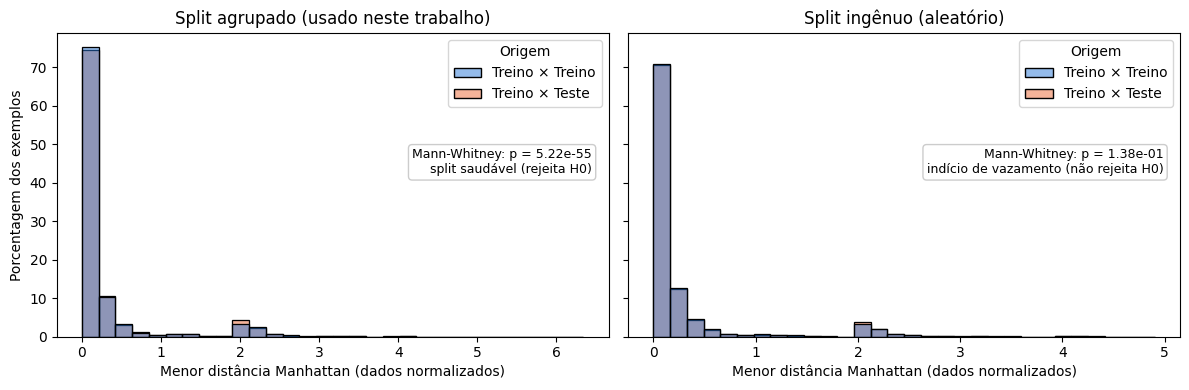

In [107]:
NIVEL_CONFIANCA = 0.95
fig, eixos = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for eixo, (titulo, (d_tt, d_te)) in zip(
    eixos, [("Split agrupado (usado neste trabalho)", d_agrupado), ("Split ingênuo (aleatório)", d_ingenuo)]
):
    dist = pd.concat([
        pd.DataFrame({"valor": d_tt, "Origem": "Treino × Treino"}),
        pd.DataFrame({"valor": d_te, "Origem": "Treino × Teste"}),
    ], ignore_index=True)
    bins = np.histogram_bin_edges(dist["valor"], bins=30)
    sns.histplot(data=dist, x="valor", hue="Origem", bins=bins, alpha=0.5, stat="percent",
                 common_norm=False, ax=eixo, palette={"Treino × Treino": "#2a78d6", "Treino × Teste": "#eb6834"})
    eixo.set(title=titulo, xlabel="Menor distância Manhattan (dados normalizados)", ylabel="Porcentagem dos exemplos")
    p_valor = stats.mannwhitneyu(d_tt, d_te, alternative="less").pvalue
    veredito = "split saudável (rejeita H0)" if p_valor < 1 - NIVEL_CONFIANCA else "indício de vazamento (não rejeita H0)"
    eixo.text(0.97, 0.62, f"Mann-Whitney: p = {p_valor:.2e}\n{veredito}", transform=eixo.transAxes,
              ha="right", va="top", fontsize=9, bbox=dict(boxstyle="round", fc="white", ec="#cccccc"))
    print(f"{titulo}: p-valor = {p_valor:.3e} | % de exemplos de teste com um 'gêmeo' idêntico no treino: "
          f"{(d_te == 0).mean():.1%}")
plt.tight_layout()
plt.show()

**Leitura do resultado.** No split ingênuo, uma grande fração dos exemplos de teste tem um "gêmeo" a distância zero no treino, e o teste de hipótese **não** rejeita H0: o split vaza informação. No split agrupado, a distância mínima entre teste e treino é maior que a distância entre exemplos do próprio treino, e o teste rejeita H0, isto é, o split é saudável. Os números exatos estão impressos acima (percentuais de "gêmeos" e p-valores).

A partir daqui, **o conjunto de teste fica guardado**. Nada é ajustado nem escolhido com ele até a Seção 10.

## 5. Análise exploratória dos dados (somente treino)

Para evitar qualquer "espiada" no conjunto de teste, **toda a análise exploratória usa apenas os dados de treino**. O objetivo é entender o problema e embasar as decisões de pré-processamento e modelagem.

In [108]:
df_eda = X_treino.copy()
df_eda["renda"] = np.where(y_treino == 1, "> 50K", "≤ 50K")
df_eda["alvo"] = y_treino.values
print(f"Linhas de treino na EDA: {len(df_eda)}")

Linhas de treino na EDA: 26112


### 5.1 O target: classes desbalanceadas

Apenas cerca de um quarto das pessoas ganha mais de US$ 50 mil. Isso tem uma consequência prática imediata: **um classificador que sempre responde "≤ 50K" já acerta cerca de 76%**. Acurácia, portanto, não é uma boa métrica aqui (era o exemplo da doença rara na aula de métricas). Voltamos a isso na Seção 6.

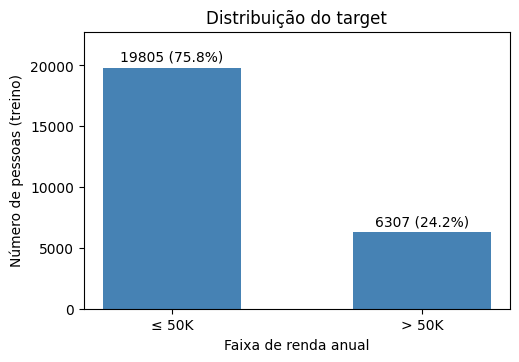

In [109]:
contagem = df_eda["renda"].value_counts().reindex(["≤ 50K", "> 50K"])

fig, eixo = plt.subplots(figsize=(5.5, 3.6))
eixo.bar(contagem.index, contagem.values,
         color="steelblue",
         width=0.55)
for i, v in enumerate(contagem.values):
    eixo.text(i, v + 300, f"{v} ({v / len(df_eda):.1%})", ha="center", va="bottom")
eixo.set(xlabel="Faixa de renda anual", ylabel="Número de pessoas (treino)", title="Distribuição do target")
eixo.set_ylim(0, contagem.max() * 1.15)
plt.show()

### 5.2 Atributos numéricos

Observações a procurar: escalas muito diferentes (importante para algoritmos sensíveis a distância e a regularização), assimetrias e valores atípicos.

In [110]:
display(X_treino[ATRIBUTOS_NUMERICOS].describe().T.round(2))

pct_gain = (X_treino["capital-gain"] == 0).mean()
pct_loss = (X_treino["capital-loss"] == 0).mean()
print(f"\n% de pessoas com ganho de capital igual a zero: {pct_gain:.1%}")
print(f"% de pessoas com perda de capital igual a zero: {pct_loss:.1%}")
print(f"Assimetria (skewness) de capital-gain: {stats.skew(X_treino['capital-gain']):.1f} | "
      f"de capital-loss: {stats.skew(X_treino['capital-loss']):.1f} | de age: {stats.skew(X_treino['age']):.2f}")

,count,mean,std,min,25%,50%,75%,max
age,26112.0,38.66,13.67,17.0,28.0,37.0,48.0,90.0
education-num,26112.0,10.07,2.57,1.0,9.0,10.0,12.0,16.0
capital-gain,26112.0,1066.28,7273.70,0.0,0.0,0.0,0.0,99999.0
capital-loss,26112.0,87.00,403.16,0.0,0.0,0.0,0.0,4356.0
hours-per-week,26112.0,40.37,12.32,1.0,40.0,40.0,45.0,99.0



% de pessoas com ganho de capital igual a zero: 91.6%
% de pessoas com perda de capital igual a zero: 95.4%
Assimetria (skewness) de capital-gain: 12.1 | de capital-loss: 4.6 | de age: 0.54


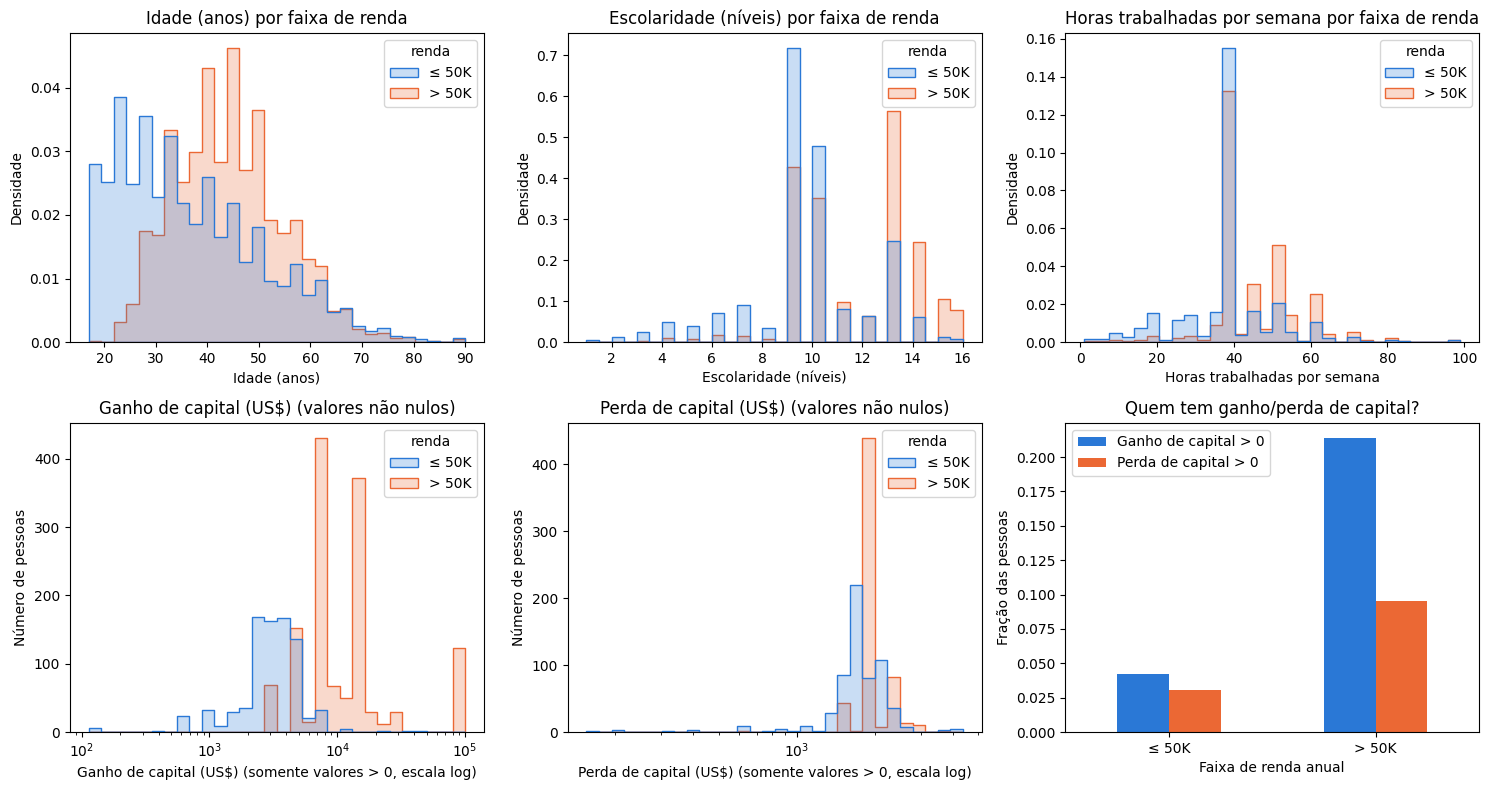

In [111]:
fig, eixos = plt.subplots(2, 3, figsize=(15, 8))
eixos = eixos.ravel()

COR_CLASSE = {"≤ 50K": "#2a78d6", "> 50K": "#eb6834"}    

for eixo, coluna in zip(eixos[:3], ["age", "education-num", "hours-per-week"]):
    sns.histplot(data=df_eda, x=coluna, hue="renda", stat="density", common_norm=False,
                 element="step", bins=30, palette=COR_CLASSE, ax=eixo, hue_order=["≤ 50K", "> 50K"])
    eixo.set(xlabel=ROTULOS[coluna], ylabel="Densidade", title=ROTULOS[coluna] + " por faixa de renda")

# capital-gain / capital-loss: a esmagadora maioria é zero, então olhamos só os valores não nulos (escala log)
for eixo, coluna in zip(eixos[3:5], ["capital-gain", "capital-loss"]):
    nao_nulos = df_eda[df_eda[coluna] > 0]
    sns.histplot(data=nao_nulos, x=coluna, hue="renda", stat="count", element="step", bins=30,
                 log_scale=True, palette=COR_CLASSE, ax=eixo, hue_order=["≤ 50K", "> 50K"])
    eixo.set(xlabel=ROTULOS[coluna] + " (somente valores > 0, escala log)", ylabel="Número de pessoas",
             title=ROTULOS[coluna] + " (valores não nulos)")

# fração com capital != 0, por classe
frac = pd.DataFrame({
    "Ganho de capital > 0": df_eda.groupby("renda")["capital-gain"].apply(lambda s: (s > 0).mean()),
    "Perda de capital > 0": df_eda.groupby("renda")["capital-loss"].apply(lambda s: (s > 0).mean()),
}).reindex(["≤ 50K", "> 50K"])
frac.plot.bar(ax=eixos[5], color=["#2a78d6", "#eb6834"], rot=0)
eixos[5].set(xlabel="Faixa de renda anual", ylabel="Fração das pessoas",
             title="Quem tem ganho/perda de capital?")
eixos[5].legend(title="")
plt.tight_layout()
plt.show()

**O que vemos.**

-   `age`, `education-num` e `hours-per-week` têm distribuições distintas entre as classes: quem ganha mais de US$ 50 mil tende a ser mais velho, mais escolarizado e a trabalhar mais horas, embora haja muita sobreposição.
-   `capital-gain` e `capital-loss` são **dominados por zeros** e, quando não nulos, variam por ordens de grandeza (distribuição extremamente assimétrica). Ter ganho de capital > 0 é muito mais comum entre quem ganha mais de US$ 50 mil.
-   As escalas dos atributos são muito diferentes (idade na casa das dezenas; ganho de capital até dezenas de milhares). Isso **exige normalização** para modelos sensíveis a distância (*k*-NN), à regularização (regressão logística) e para o PCA. Para os ganhos e perdas de capital, aplicaremos antes um `log(1 + x)`, que não tem etapa de ajuste (logo não causa vazamento) e comprime a cauda longa.

### 5.3 Atributos categóricos e a taxa de renda > 50K

Para cada categoria, mostramos a **proporção de pessoas com renda > 50K** (barra) e o **número de pessoas** (texto). A linha vertical tracejada é a taxa geral do treino. Categorias com poucas pessoas têm taxas pouco confiáveis; para `native-country` mostramos só as 10 mais frequentes.

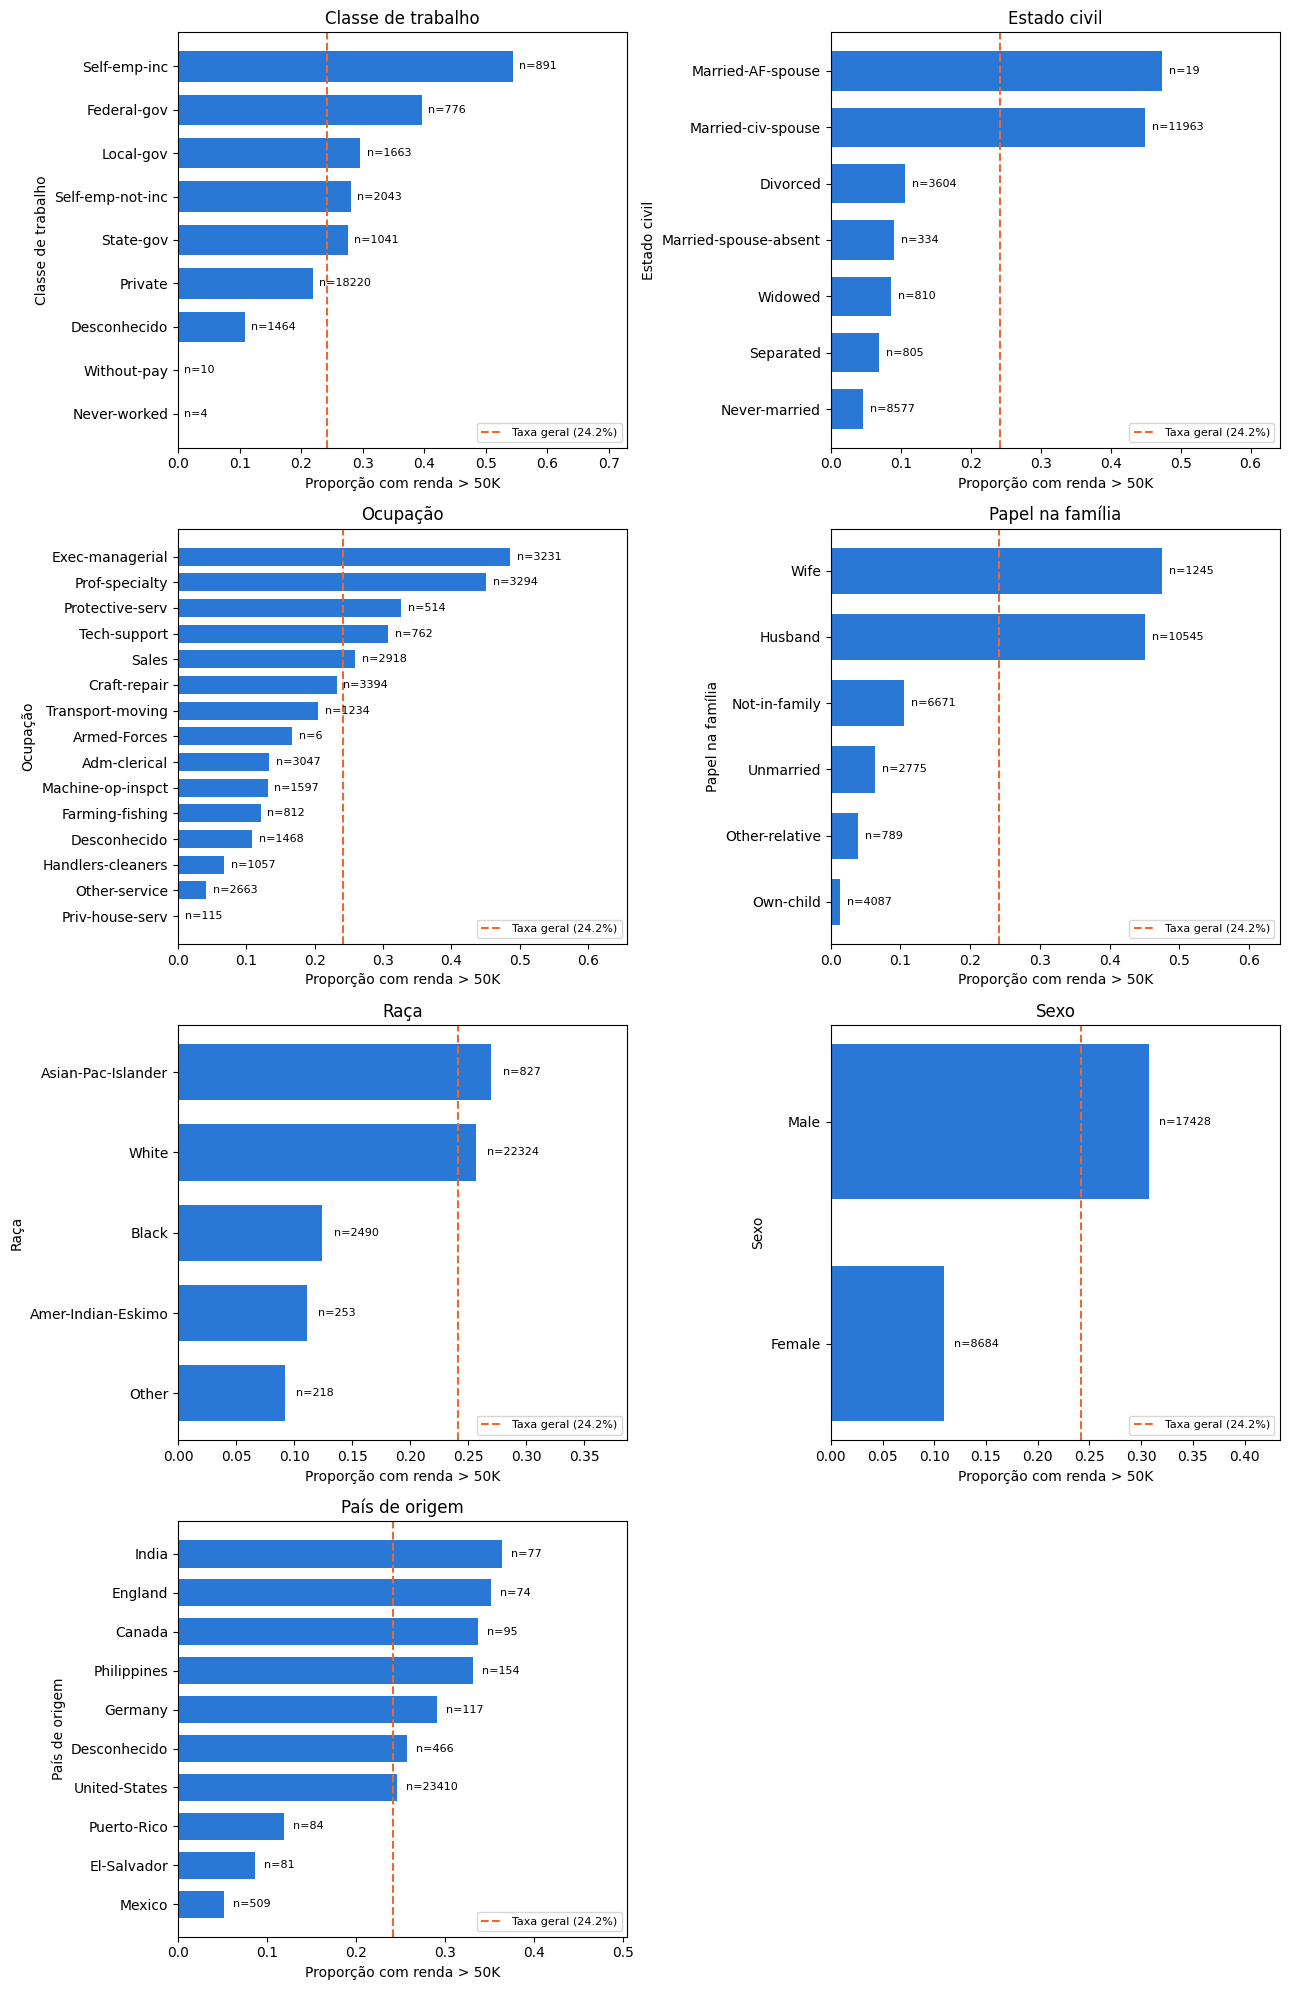

In [112]:
taxa_geral = y_treino.mean()

def plota_taxa(eixo, coluna, top=None):
    tabela = (df_eda.assign(cat=df_eda[coluna].fillna("Desconhecido"))
              .groupby("cat")["alvo"].agg(taxa="mean", n="size"))
    if top:
        tabela = tabela.sort_values("n", ascending=False).head(top)
    tabela = tabela.sort_values("taxa")
    eixo.barh(tabela.index, tabela["taxa"], color="#2a78d6", height=0.7)
    for i, (taxa, n) in enumerate(zip(tabela["taxa"], tabela["n"])):
        eixo.text(taxa + 0.01, i, f"n={n}", va="center", fontsize=8)
    eixo.axvline(taxa_geral, color="#eb6834", linestyle="--", label=f"Taxa geral ({taxa_geral:.1%})")
    eixo.set(xlabel="Proporção com renda > 50K", ylabel=ROTULOS[coluna], title=ROTULOS[coluna])
    eixo.set_xlim(0, min(1.0, tabela["taxa"].max() * 1.25 + 0.05))
    eixo.legend(loc="lower right", fontsize=8)

fig, eixos = plt.subplots(4, 2, figsize=(13, 20))
eixos = eixos.ravel()
for eixo, coluna in zip(eixos, ATRIBUTOS_CATEGORICOS):
    plota_taxa(eixo, coluna, top=10 if coluna == "native-country" else None)
eixos[-1].axis("off")
plt.tight_layout()
plt.show()

**O que vemos.** O estado civil e o papel na família são **muito discriminativos**: pessoas casadas (`Married-civ-spouse`, `Husband`, `Wife`) têm taxa de renda alta bem acima da geral, enquanto "nunca casado" e `Own-child` têm taxas muito baixas. Ocupações executivas e profissionais liberais têm taxas altas; serviços e limpeza, baixas. Há também diferença por sexo e por raça (voltaremos a isso na Seção 13, sobre equidade).


### 5.4 Dados faltantes: a ausência é informativa?

A taxa de renda alta é **bem menor** entre quem tem `workclass`/`occupation` ausentes (em geral, pessoas fora da força de trabalho formal), e os dois atributos faltam quase sempre juntos. Logo, descartar essas linhas jogaria fora padrões reais, e imputar a moda esconderia a informação. Tratar o ausente como categoria `Desconhecido` preserva o sinal.

In [113]:
linhas = []
for coluna in ["workclass", "occupation", "native-country"]:
    ausente = df_eda[coluna].isna()
    linhas.append({
        "atributo": coluna,
        "% ausente": ausente.mean() * 100,
        "taxa > 50K se ausente": df_eda.loc[ausente, "alvo"].mean() * 100,
        "taxa > 50K se presente": df_eda.loc[~ausente, "alvo"].mean() * 100,
    })
display(pd.DataFrame(linhas).set_index("atributo").round(2))

ausente_wc = df_eda["workclass"].isna()
ausente_oc = df_eda["occupation"].isna()
print("\nLinhas em que workclass e occupation faltam juntas:",
      f"{(ausente_wc & ausente_oc).sum()} de {max(ausente_wc.sum(), ausente_oc.sum())}")

,% ausente,taxa > 50K se ausente,taxa > 50K se presente
atributo,,,
workclass,5.61,10.86,24.94
occupation,5.62,10.83,24.95
native-country,1.78,25.75,24.12



Linhas em que workclass e occupation faltam juntas: 1464 de 1468


### 5.5 Relações entre atributos (redundância)

Duas visões: a correlação de **Spearman** entre os atributos numéricos e o target (adequada a distribuições assimétricas) e o **V de Cramér** entre atributos categóricos, uma medida de associação entre 0 (independentes) e 1 (totalmente associados), obtida a partir do qui-quadrado.

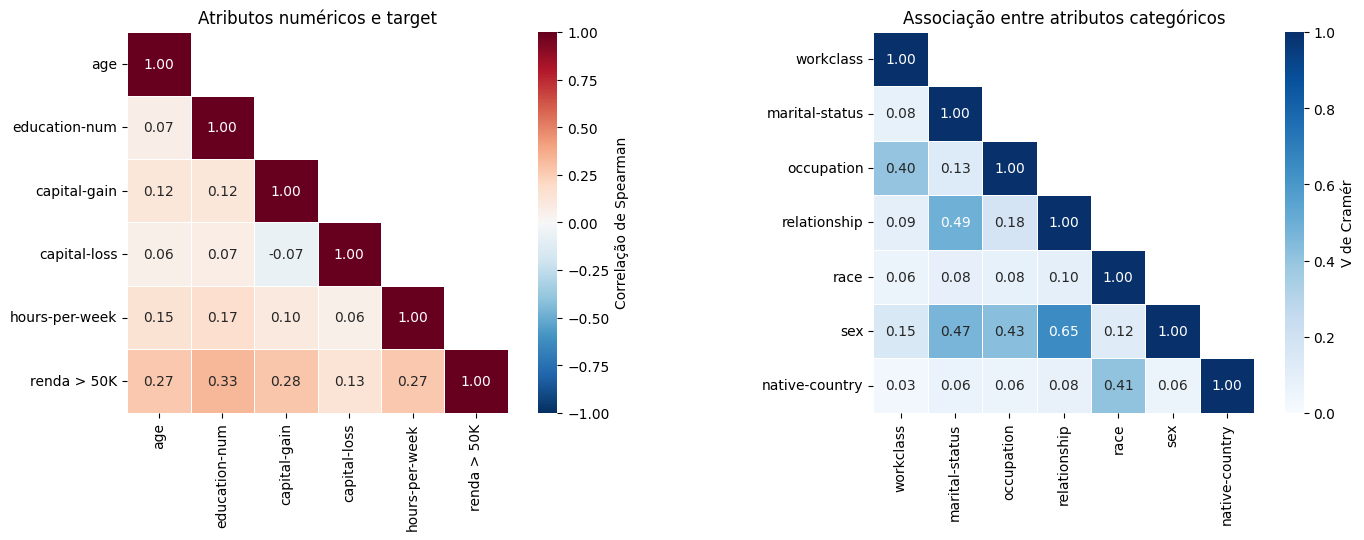

In [114]:
def cramer_v(x, y):
    """V de Cramér com correção de viés (Bergsma, 2013)."""
    tabela = pd.crosstab(x, y)
    chi2 = stats.chi2_contingency(tabela, correction=False)[0]
    n = tabela.to_numpy().sum()
    phi2 = chi2 / n
    r, k = tabela.shape
    phi2_corr = max(0, phi2 - (k - 1) * (r - 1) / (n - 1))
    r_corr = r - (r - 1) ** 2 / (n - 1)
    k_corr = k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2_corr / max(1e-12, min(k_corr - 1, r_corr - 1)))

cat_eda = df_eda[ATRIBUTOS_CATEGORICOS].fillna("Desconhecido")
v_cramer = pd.DataFrame(
    [[cramer_v(cat_eda[a], cat_eda[b]) for b in ATRIBUTOS_CATEGORICOS] for a in ATRIBUTOS_CATEGORICOS],
    index=ATRIBUTOS_CATEGORICOS, columns=ATRIBUTOS_CATEGORICOS,
)
corr_spearman = df_eda[ATRIBUTOS_NUMERICOS + ["alvo"]].corr(method="spearman")
corr_spearman = corr_spearman.rename(index={"alvo": "renda > 50K"}, columns={"alvo": "renda > 50K"})

fig, eixos = plt.subplots(1, 2, figsize=(15, 5.5))
mascara = np.triu(np.ones_like(corr_spearman, dtype=bool), k=1)
sns.heatmap(corr_spearman, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, ax=eixos[0], cbar_kws={"label": "Correlação de Spearman"})
eixos[0].set_title("Atributos numéricos e target")
mascara = np.triu(np.ones_like(v_cramer, dtype=bool), k=1)
sns.heatmap(v_cramer, mask=mascara, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            square=True, linewidths=0.5, ax=eixos[1], cbar_kws={"label": "V de Cramér"})
eixos[1].set_title("Associação entre atributos categóricos")
plt.tight_layout()
plt.show()

**O que vemos.** Os atributos categóricos **não são independentes**: `relationship` e `marital-status` (e também `sex`) são fortemente associados, o que faz sentido (marido/esposa ↔ casado). Essa redundância, somada às dezenas de colunas geradas pelo *one-hot*, é a motivação para testar **seleção de atributos e PCA** (Q2). Entre os numéricos, `education-num`, `age` e `hours-per-week` se correlacionam positivamente com a renda.

### 5.6 Quais atributos carregam informação sobre o target? (informação mútua)

A **informação mútua** mede o quanto conhecer um atributo reduz a incerteza sobre o target, **sem supor relação linear**. Incluímos duas colunas de referência: o `fnlwgt` (que removemos) e uma coluna de **ruído aleatório** (a informação mútua de ruído indica o "piso" de erro da estimativa).

age               0.067148
education-num     0.067463
capital-gain      0.081825
marital-status    0.108509
relationship      0.114577
dtype: float64

ruído aleatório (referência)    0.000000
fnlwgt (removido)               0.026962
dtype: float64


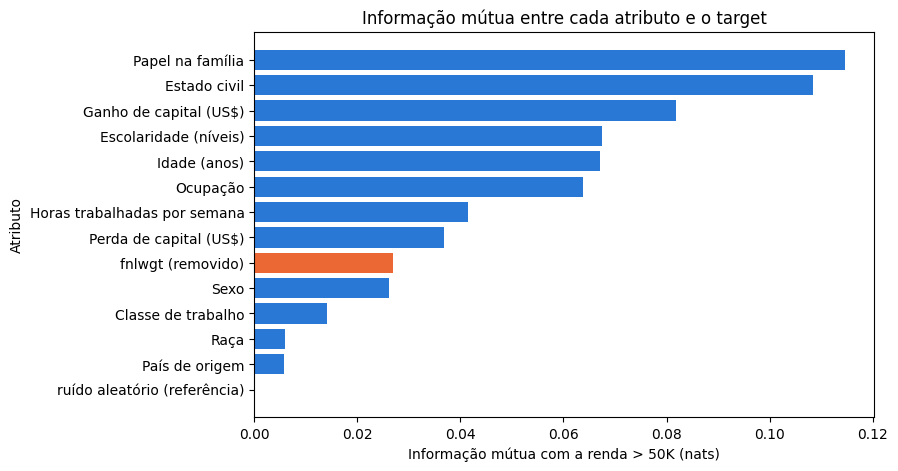

In [115]:
rng = np.random.default_rng(SEMENTE)
bruto_treino = df_bruto.iloc[indices_treino].reset_index(drop=True)

mi_df = X_treino.copy()
mi_df["fnlwgt (removido)"] = bruto_treino["fnlwgt"].values
mi_df["ruído aleatório (referência)"] = rng.normal(size=len(mi_df))

mi_df[ATRIBUTOS_CATEGORICOS] = mi_df[ATRIBUTOS_CATEGORICOS].fillna("Desconhecido")
colunas_mi = list(mi_df.columns)
eh_discreto = [c in ATRIBUTOS_CATEGORICOS for c in colunas_mi]
mi_X = mi_df.copy()
mi_X[ATRIBUTOS_CATEGORICOS] = OrdinalEncoder().fit_transform(mi_df[ATRIBUTOS_CATEGORICOS])

mi = mutual_info_classif(mi_X, y_treino, discrete_features=eh_discreto, random_state=SEMENTE)
mi = pd.Series(mi, index=colunas_mi).sort_values()

fig, eixo = plt.subplots(figsize=(8, 5))
cores = ["#eb6834" if c.startswith(("fnlwgt", "ruído")) else "#2a78d6" for c in mi.index]
eixo.barh([ROTULOS.get(c, c) for c in mi.index], mi.values, color=cores)
eixo.set(xlabel="Informação mútua com a renda > 50K (nats)", ylabel="Atributo",
         title="Informação mútua entre cada atributo e o target")
print(mi.tail(5))
print()
print(mi[mi.index.str.contains("ruído|fnlwgt", case=False)])
plt.show()


Os atributos mais informativos são `relationship`, `marital-status`, `capital-gain`, `age`, `education-num` e `occupation`. O `fnlwgt` (laranja) tem informação mútua **acima** do ruído aleatório e comparável à de `sex`, então **não** podemos dizer que ele seja "inútil" só por este gráfico (o estimador também tende a inflar a informação de variáveis contínuas com muitos valores distintos). A remoção continua sendo uma decisão **conceitual**, explicada na Seção 3.3: o `fnlwgt` descreve o desenho amostral do censo, não a pessoa, e um modelo que o use estaria aprendendo sobre a amostragem e não sobre a renda. Atributos como `race` e `native-country` carregam pouca informação marginal.

### 5.7 Síntese da EDA e decisões de modelagem

| Achado | Decisão |
|---|---|
| Classes desbalanceadas (~24% positivas) | Não usar acurácia como métrica principal. Otimizar **PR-AUC**; reportar também ROC-AUC, F1, acurácia balanceada; usar validação cruzada **estratificada**. |
| Exemplos redundantes | Divisão e validação cruzada **agrupadas** (`StratifiedGroupKFold`). |
| Escalas muito diferentes; `capital-*` muito assimétricos | Normalizar (padrão ou min-max, escolhido pelo Optuna) nos modelos sensíveis à escala; aplicar `log(1+x)` aos `capital-*`. Árvores e *boosting* não precisam de normalização. |
| Ausentes informativos | Categoria `Desconhecido` dentro do pipeline. |
| Categorias raras (ex.: países com poucas pessoas) | Deixar o Optuna escolher a **frequência mínima** abaixo da qual categorias são agrupadas no *one-hot*. |
| Redundância entre atributos e muitas colunas após *one-hot* | Deixar o Optuna controlar **seleção de atributos / PCA** em regressão logística e *k*-NN. |
| `fnlwgt` é peso amostral (não descreve a pessoa); `education` é redundante com `education-num` | Removidos. |

## 6. Estratégia de avaliação

### 6.1 Métricas

Como o target é desbalanceado, usamos métricas que não se enganam com a classe majoritária. Seja a classe positiva "renda > 50K" e VP, FP, VN, FN os valores da matriz de confusão (como na aula de métricas):

| Métrica | Definição | Intuição |
|---|---|---|
| **PR-AUC** (*average precision*) | área sob a curva precisão × sensibilidade | **Métrica de otimização**. Resume o equilíbrio entre precisão e sensibilidade em *todos* os limiares, e é a recomendada para dados desbalanceados [4]. Um modelo que chuta ao acaso tem PR-AUC ≈ proporção de positivos (~0,24). |
| **ROC-AUC** | área sob a curva sensibilidade × (1 − especificidade) | Probabilidade de um positivo qualquer receber probabilidade maior que um negativo qualquer. Chute: 0,5. Pode parecer otimista com desbalanceamento. |
| **F1** | $\frac{2VP}{2VP + FP + FN}$ | Média harmônica de precisão e sensibilidade, **depende do limiar** (padrão 0,5). |
| **Acurácia balanceada** | média da sensibilidade das duas classes | Acurácia que "pesa" as classes igualmente. |
| **Precisão / Sensibilidade** | $\frac{VP}{VP+FP}$ / $\frac{VP}{VP+FN}$ | Dos que prevemos > 50K, quantos de fato são? / Dos que são > 50K, quantos achamos? |
| **MCC** | correlação entre previsão e verdade | Resumo único robusto a desbalanceamento. |

**Por que otimizar uma métrica que não depende de limiar?** Porque o limiar de decisão (0,5 por padrão) é uma escolha *separada* do modelo; otimizá-lo é tema da Seção 11. Assim, a busca de hiperparâmetros se concentra na **qualidade do ranqueamento** das probabilidades.

### 6.2 Validação cruzada estratificada e agrupada

Todos os modelos são avaliados com `StratifiedGroupKFold` (5 folds) **dentro do conjunto de treino**:

-   *estratificada*: cada fold mantém a proporção de ~24% de positivos;
-   *agrupada*: um mesmo grupo de exemplos quase redundantes nunca fica em dois folds diferentes (mesmo cuidado da Seção 4, agora para o treino × validação).

Durante a otimização, **todas as tentativas usam exatamente os mesmos folds** (semente fixa), para que a comparação entre configurações seja justa.